# ___Home Loan Default - Risk Management___

# Business Problem 

The goal of this project is to build a predictive model that assesses the credit risk of home loan applicants, especially those with little to no credit history. By accurately identifying potential defaulters (Target 1), the bank can significantly reduce its Non-Performing Assets (NPAs) and minimize financial losses. At the same time, the model aims to ensure that eligible, safe borrowers (Target 0) are not unfairly rejected, thereby optimizing the bank's loan approval rates and maximizing interest revenue.

# Data Description

### ●	application_train.csv
-	The main file which contains the Target(1:Defaulter ; 0: Not Defaulter)
-	Static data for all applications. One row represents one loan in our data sample.
### ●	bureau.csv
-	All client's previous credits provided by other financial institutions that were reported to Credit Bureau (for clients who have a loan in our sample).
-	For every loan in our sample, there are as many rows as number of credits the client had in Credit Bureau before the application date.
### ●	bureau_balance.csv
-	Monthly balances of previous credits in Credit Bureau.
-	This table has one row for each month of history of every previous credit reported to Credit Bureau – i.e the table has (#loans in sample * # of relative previous credits * # of months where we have some history observable for the previous credits) rows.
### ●	POS_CASH_balance.csv
-	Monthly balance snapshots of previous POS (point of sales) and cash loans that the applicant had with Home Credit.
-	This table has one row for each month of history of every previous credit in Home Credit (consumer credit and cash loans) related to loans in our sample – i.e. the table has (#loans in sample * # of relative previous credits * # of months in which we have some history observable for the previous credits) rows.
### ●	credit_card_balance.csv
-	Monthly balance snapshots of previous credit cards that the applicant has with Home Credit.
-	This table has one row for each month of history of every previous credit in Home Credit (consumer credit and cash loans) related to loans in our sample – i.e. the table has (#loans in sample * # of relative previous credit cards * # of months where we have some history observable for the previous credit card) rows.
### ●	previous_application.csv
-	All previous applications for Home Credit loans of clients who have loans in our sample.
-	There is one row for each previous application related to loans in our data sample.
### ●	installments_payments.csv
-	Repayment history for the previously disbursed credits in Home Credit related to the loans in our sample.
-	There is a) one row for every payment that was made plus b) one row each for missed payment.
-	One row is equivalent to one payment of one installment OR one installment corresponding to one payment of one previous Home Credit credit related to loans in our sample.


In [1]:
## Import Necessery Libraries 

import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns

## ignore Warnings
import warnings
warnings.filterwarnings('ignore')

In [2]:
## OPTIMIZED DATA LOADING & DOWN-SAMPLING (To Prevent Memory Crash)

print("Loading datasets with memory optimization...")

## In this Data set useing 50000 samle data because system crash issue and proper handle the data in a low level system 
app_train = pd.read_csv('application_train.csv').sample(n=50000, random_state=42).reset_index(drop=True)
valid_ids = app_train['SK_ID_CURR'].unique()

def load_and_filter(filename):
    """Bade tables ko chunk me load karke sirf valid customer IDs ka data rakhna"""
    chunks = []
    for chunk in pd.read_csv(filename, chunksize=50000):
        filtered_chunk = chunk[chunk['SK_ID_CURR'].isin(valid_ids)]
        chunks.append(filtered_chunk)
    return pd.concat(chunks, axis=0)

bureau = load_and_filter('bureau.csv')
bureau_balance = pd.read_csv('bureau_balance.csv') # In this dataset is SK_ID_BUREAU 
prev_app = load_and_filter('previous_application.csv')
pos_cash = load_and_filter('POS_CASH_balance.csv')
credit_card = load_and_filter('credit_card_balance.csv')
installments = load_and_filter('installments_payments.csv')

print("All 7 Datasets Loaded Successfully!")

Loading datasets with memory optimization...
All 7 Datasets Loaded Successfully!


In [3]:
app_train.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,384575,0,Cash loans,M,Y,N,2,207000.0,465457.5,52641.0,...,0,0,0,0,0.0,0.0,0.0,1.0,0.0,1.0
1,214010,0,Cash loans,F,Y,Y,0,247500.0,1281712.5,48946.5,...,0,0,0,0,0.0,0.0,0.0,1.0,0.0,3.0
2,142232,0,Cash loans,F,Y,N,0,202500.0,495000.0,39109.5,...,0,0,0,0,0.0,0.0,0.0,1.0,0.0,3.0
3,389171,0,Cash loans,F,N,Y,0,247500.0,254700.0,24939.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
4,283617,0,Cash loans,M,N,Y,0,112500.0,308133.0,15862.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,4.0


In [4]:
bureau.head()

,SK_ID_CURR,SK_ID_BUREAU,CREDIT_ACTIVE,CREDIT_CURRENCY,DAYS_CREDIT,CREDIT_DAY_OVERDUE,DAYS_CREDIT_ENDDATE,DAYS_ENDDATE_FACT,AMT_CREDIT_MAX_OVERDUE,CNT_CREDIT_PROLONG,AMT_CREDIT_SUM,AMT_CREDIT_SUM_DEBT,AMT_CREDIT_SUM_LIMIT,AMT_CREDIT_SUM_OVERDUE,CREDIT_TYPE,DAYS_CREDIT_UPDATE,AMT_ANNUITY
21,222183,5714491,Active,currency 1,-784,0,1008.0,NaN,0.00,0,0.0,-411.615,411.615,0.0,Credit card,-694,NaN
22,222183,5714492,Active,currency 1,-774,0,625.0,NaN,NaN,0,127840.5,0.000,0.000,0.0,Credit card,-210,NaN
23,222183,5714493,Active,currency 1,-395,0,1431.0,NaN,NaN,0,1350000.0,1185493.500,0.000,0.0,Consumer credit,-24,NaN
24,222183,5714495,Closed,currency 1,-2744,0,-2561.0,-2559.0,310.50,0,18157.5,NaN,NaN,0.0,Consumer credit,-2559,NaN
25,222183,5714496,Closed,currency 1,-1103,0,-7.0,-343.0,20493.27,0,675000.0,0.000,0.000,0.0,Consumer credit,-343,NaN


In [5]:
prev_app.head()

,SK_ID_PREV,SK_ID_CURR,NAME_CONTRACT_TYPE,AMT_ANNUITY,AMT_APPLICATION,AMT_CREDIT,AMT_DOWN_PAYMENT,AMT_GOODS_PRICE,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,...,NAME_SELLER_INDUSTRY,CNT_PAYMENT,NAME_YIELD_GROUP,PRODUCT_COMBINATION,DAYS_FIRST_DRAWING,DAYS_FIRST_DUE,DAYS_LAST_DUE_1ST_VERSION,DAYS_LAST_DUE,DAYS_TERMINATION,NFLAG_INSURED_ON_APPROVAL
0,2030495,271877,Consumer loans,1730.43,17145.0,17145.0,0.0,17145.0,SATURDAY,15,...,Connectivity,12.0,middle,POS mobile with interest,365243.0,-42.0,300.0,-42.0,-37.0,0.0
8,2367563,342292,Cash loans,NaN,0.0,0.0,NaN,NaN,MONDAY,15,...,XNA,NaN,XNA,Cash,NaN,NaN,NaN,NaN,NaN,NaN
10,1715995,447712,Cash loans,11368.62,270000.0,335754.0,NaN,270000.0,FRIDAY,7,...,XNA,54.0,low_normal,Cash X-Sell: low,365243.0,-705.0,885.0,-345.0,-334.0,1.0
34,1629736,255331,Revolving loans,10125.00,202500.0,202500.0,NaN,202500.0,SATURDAY,14,...,XNA,0.0,XNA,Card X-Sell,-265.0,-234.0,365243.0,365243.0,365243.0,0.0
55,2741581,383645,Cash loans,47407.50,450000.0,450000.0,NaN,450000.0,MONDAY,13,...,XNA,12.0,middle,Cash X-Sell: middle,365243.0,-527.0,-197.0,-197.0,-194.0,0.0


# Basic Checks

In [6]:
app_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Columns: 122 entries, SK_ID_CURR to AMT_REQ_CREDIT_BUREAU_YEAR
dtypes: float64(65), int64(41), object(16)
memory usage: 46.5+ MB


In [7]:
## check statistical information for app_train data

app_train.describe()

,SK_ID_CURR,TARGET,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
count,50000.000000,50000.000000,50000.000000,5.000000e+04,5.000000e+04,49998.000000,4.995500e+04,50000.000000,50000.00000,50000.000000,...,50000.000000,50000.000000,50000.000000,50000.00000,43204.000000,43204.000000,43204.000000,43204.000000,43204.000000,43204.000000
mean,277922.792300,0.080460,0.417860,1.702592e+05,5.977463e+05,27113.515871,5.368328e+05,0.020894,-16037.22864,63756.103260,...,0.007920,0.000700,0.000600,0.00038,0.006458,0.008425,0.035460,0.269628,0.260670,1.896723
std,102627.575389,0.272007,0.727038,5.372203e+05,3.999173e+05,14495.194361,3.666133e+05,0.013869,4370.81374,141231.876938,...,0.088642,0.026449,0.024488,0.01949,0.085144,0.132539,0.207138,0.928304,0.609136,1.868220
min,100002.000000,0.000000,0.000000,2.610000e+04,4.500000e+04,1980.000000,4.500000e+04,0.000290,-25197.00000,-16852.000000,...,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,189456.500000,0.000000,0.000000,1.125000e+05,2.700000e+05,16582.500000,2.385000e+05,0.010006,-19681.00000,-2779.250000,...,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,278094.000000,0.000000,0.000000,1.475235e+05,5.123385e+05,24939.000000,4.500000e+05,0.018850,-15748.00000,-1220.000000,...,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
75%,366733.750000,0.000000,1.000000,2.025000e+05,8.086500e+05,34573.500000,6.795000e+05,0.028663,-12415.00000,-292.000000,...,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000
max,456247.000000,1.000000,12.000000,1.170000e+08,4.050000e+06,230161.500000,4.050000e+06,0.072508,-7673.00000,365243.000000,...,1.000000,1.000000,1.000000,1.00000,4.000000,8.000000,6.000000,22.000000,7.000000,23.000000


In [8]:
bureau.info()

<class 'pandas.core.frame.DataFrame'>
Index: 237076 entries, 21 to 1716427
Data columns (total 17 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   SK_ID_CURR              237076 non-null  int64  
 1   SK_ID_BUREAU            237076 non-null  int64  
 2   CREDIT_ACTIVE           237076 non-null  object 
 3   CREDIT_CURRENCY         237076 non-null  object 
 4   DAYS_CREDIT             237076 non-null  int64  
 5   CREDIT_DAY_OVERDUE      237076 non-null  int64  
 6   DAYS_CREDIT_ENDDATE     222696 non-null  float64
 7   DAYS_ENDDATE_FACT       148791 non-null  float64
 8   AMT_CREDIT_MAX_OVERDUE  83606 non-null   float64
 9   CNT_CREDIT_PROLONG      237076 non-null  int64  
 10  AMT_CREDIT_SUM          237076 non-null  float64
 11  AMT_CREDIT_SUM_DEBT     201060 non-null  float64
 12  AMT_CREDIT_SUM_LIMIT    158078 non-null  float64
 13  AMT_CREDIT_SUM_OVERDUE  237076 non-null  float64
 14  CREDIT_TYPE            

In [9]:
## check statistical information for bureau data

bureau.describe()

,SK_ID_CURR,SK_ID_BUREAU,DAYS_CREDIT,CREDIT_DAY_OVERDUE,DAYS_CREDIT_ENDDATE,DAYS_ENDDATE_FACT,AMT_CREDIT_MAX_OVERDUE,CNT_CREDIT_PROLONG,AMT_CREDIT_SUM,AMT_CREDIT_SUM_DEBT,AMT_CREDIT_SUM_LIMIT,AMT_CREDIT_SUM_OVERDUE,DAYS_CREDIT_UPDATE,AMT_ANNUITY
count,237076.000000,2.370760e+05,237076.000000,237076.000000,222696.000000,148791.000000,8.360600e+04,237076.000000,2.370760e+05,2.010600e+05,1.580780e+05,237076.000000,237076.000000,5.417700e+04
mean,277969.435818,5.891002e+06,-1145.793783,0.820636,485.968015,-1026.347938,3.331803e+03,0.007179,3.485180e+05,1.358216e+05,6.423701e+03,25.185922,-601.997773,1.383250e+04
std,102731.278767,5.382395e+05,801.263026,36.731687,4958.847219,718.136916,4.741148e+04,0.102067,1.194566e+06,6.322418e+05,4.392610e+04,2882.334119,765.486846,1.286849e+05
min,100002.000000,5.000019e+06,-2922.000000,0.000000,-42041.000000,-2916.000000,0.000000e+00,0.000000,0.000000e+00,-1.354876e+06,-1.219057e+05,0.000000,-41943.000000,0.000000e+00
25%,189069.000000,5.416711e+06,-1676.000000,0.000000,-1151.000000,-1509.000000,0.000000e+00,0.000000,5.139450e+04,0.000000e+00,0.000000e+00,0.000000,-905.000000,0.000000e+00
50%,277876.000000,5.858440e+06,-990.000000,0.000000,-337.000000,-904.000000,0.000000e+00,0.000000,1.251000e+05,0.000000e+00,0.000000e+00,0.000000,-407.000000,6.660000e+02
75%,366842.000000,6.367059e+06,-469.000000,0.000000,473.000000,-430.000000,0.000000e+00,0.000000,3.060000e+05,4.050675e+04,0.000000e+00,0.000000,-33.000000,1.396800e+04
max,456247.000000,6.843447e+06,-1.000000,2703.000000,31199.000000,0.000000,9.231525e+06,9.000000,3.960000e+08,5.963769e+07,2.207250e+06,959386.500000,13.000000,2.401604e+07


In [10]:
prev_app.info()

<class 'pandas.core.frame.DataFrame'>
Index: 229715 entries, 0 to 1670212
Data columns (total 37 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   SK_ID_PREV                   229715 non-null  int64  
 1   SK_ID_CURR                   229715 non-null  int64  
 2   NAME_CONTRACT_TYPE           229715 non-null  object 
 3   AMT_ANNUITY                  179888 non-null  float64
 4   AMT_APPLICATION              229715 non-null  float64
 5   AMT_CREDIT                   229715 non-null  float64
 6   AMT_DOWN_PAYMENT             108518 non-null  float64
 7   AMT_GOODS_PRICE              177863 non-null  float64
 8   WEEKDAY_APPR_PROCESS_START   229715 non-null  object 
 9   HOUR_APPR_PROCESS_START      229715 non-null  int64  
 10  FLAG_LAST_APPL_PER_CONTRACT  229715 non-null  object 
 11  NFLAG_LAST_APPL_IN_DAY       229715 non-null  int64  
 12  RATE_DOWN_PAYMENT            108518 non-null  float64
 13  RAT

In [11]:
## check statistical information for prev_app data

prev_app.describe()

,SK_ID_PREV,SK_ID_CURR,AMT_ANNUITY,AMT_APPLICATION,AMT_CREDIT,AMT_DOWN_PAYMENT,AMT_GOODS_PRICE,HOUR_APPR_PROCESS_START,NFLAG_LAST_APPL_IN_DAY,RATE_DOWN_PAYMENT,...,RATE_INTEREST_PRIVILEGED,DAYS_DECISION,SELLERPLACE_AREA,CNT_PAYMENT,DAYS_FIRST_DRAWING,DAYS_FIRST_DUE,DAYS_LAST_DUE_1ST_VERSION,DAYS_LAST_DUE,DAYS_TERMINATION,NFLAG_INSURED_ON_APPROVAL
count,2.297150e+05,229715.000000,179888.000000,2.297150e+05,2.297150e+05,1.085180e+05,1.778630e+05,229715.000000,229715.000000,108518.000000,...,750.000000,229715.000000,2.297150e+05,179890.000000,138729.000000,138729.000000,138729.000000,138729.000000,138729.000000,138729.000000
mean,1.922245e+06,277716.978199,15788.119704,1.743294e+05,1.952928e+05,6.551906e+03,2.251745e+05,12.488066,0.996635,0.079697,...,0.764188,-882.505509,3.115108e+02,15.999817,342164.231862,13460.841490,33280.962517,76760.621226,82447.680009,0.327992
std,5.325713e+05,102616.798860,14622.857755,2.915747e+05,3.173768e+05,1.757157e+04,3.136393e+05,3.338456,0.057911,0.106792,...,0.103792,783.866196,8.483098e+03,14.549255,88999.332081,71587.904911,106176.030853,149774.163256,153601.152575,0.469484
min,1.000004e+06,100002.000000,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,...,0.424419,-2922.000000,-1.000000e+00,0.000000,-2921.000000,-2891.000000,-2801.000000,-2869.000000,-2845.000000,0.000000
25%,1.461883e+06,189100.000000,6260.017500,1.980000e+04,2.501100e+04,0.000000e+00,4.995000e+04,10.000000,1.000000,0.000000,...,0.662526,-1320.000000,-1.000000e+00,6.000000,365243.000000,-1632.000000,-1249.000000,-1318.000000,-1271.000000,0.000000
50%,1.921030e+06,278095.000000,11165.040000,7.101000e+04,8.046000e+04,1.791000e+03,1.096110e+05,12.000000,1.000000,0.062459,...,0.835095,-585.000000,4.000000e+00,12.000000,365243.000000,-828.000000,-363.000000,-537.000000,-497.000000,0.000000
75%,2.382528e+06,366236.000000,20378.227500,1.800000e+05,2.129602e+05,7.731000e+03,2.295000e+05,15.000000,1.000000,0.108909,...,0.852537,-271.000000,8.900000e+01,24.000000,365243.000000,-409.000000,132.000000,-74.000000,-43.000000,1.000000
max,2.845378e+06,456247.000000,418058.145000,4.455000e+06,4.104351e+06,1.404000e+06,4.455000e+06,23.000000,1.000000,0.930197,...,0.867336,-2.000000,4.000000e+06,84.000000,365243.000000,365243.000000,365243.000000,365243.000000,365243.000000,1.000000


In [12]:
#check shape of data

print(f"Main Train Shape: {app_train.shape}")
print(f"Bureau Shape: {bureau.shape}")
print(f"Previous App Shape: {prev_app.shape}")
print(f"Main Train Shape: {bureau_balance.shape}")
print(f"Bureau Shape: {pos_cash.shape}")
print(f"Previous App Shape: {credit_card.shape}")
print(f"Previous App Shape: {installments.shape}")

Main Train Shape: (50000, 122)
Bureau Shape: (237076, 17)
Previous App Shape: (229715, 37)
Main Train Shape: (27299925, 3)
Bureau Shape: (1392087, 8)
Previous App Shape: (520583, 23)
Previous App Shape: (1881881, 8)


# 2. Exploratory Data Analysis

### 2.1 Check Imbalance Target Variable

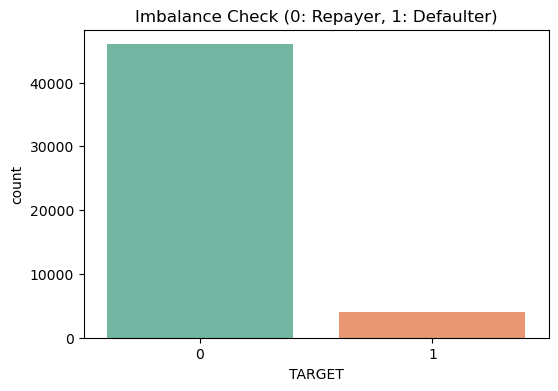

In [13]:
## Check Imbalance Target Variable
plt.figure(figsize=(6,4))
sns.countplot(x='TARGET', data=app_train, palette='Set2')
plt.title('Imbalance Check (0: Repayer, 1: Defaulter)')
plt.show()

### 2.2  Check Anomly/Outliers Detection

In [14]:
## Check Anomly/Outliers Detection

print("\n[Insight 1] Analyzing Employment Days Anomaly:")
anom = app_train[app_train['DAYS_EMPLOYED'] == 365243]
non_anom = app_train[app_train['DAYS_EMPLOYED'] != 365243]
print(f"Total entries with 1000-year employment error: {len(anom)}")
print(f"Defaulter rate among anomalous group: {100 * anom['TARGET'].mean():.2f}%")
print(f"Defaulter rate among clean group: {100 * non_anom['TARGET'].mean():.2f}%")


[Insight 1] Analyzing Employment Days Anomaly:
Total entries with 1000-year employment error: 8996
Defaulter rate among anomalous group: 5.41%
Defaulter rate among clean group: 8.62%


In [15]:
# Cleaning the Anomaly inline for modeling

app_train['DAYS_EMPLOYED_ANOM'] = app_train["DAYS_EMPLOYED"] == 365243
app_train['DAYS_EMPLOYED'].replace({365243: np.nan}, inplace=True)

### 2.3 KDE Distribution Plot: Customer Age vs Default Risk

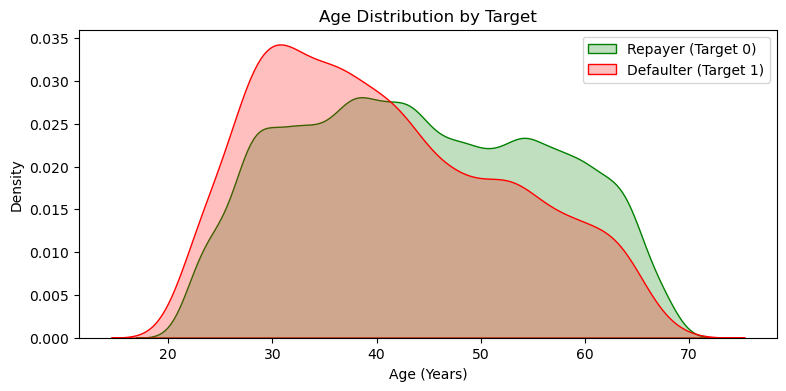

In [16]:
## KDE Distribution Plot: Customer Age vs Default Risk

plt.figure(figsize=(9, 4))
sns.kdeplot(app_train.loc[app_train['TARGET'] == 0, 'DAYS_BIRTH'] / -365, label='Repayer (Target 0)', shade=True, color='g')
sns.kdeplot(app_train.loc[app_train['TARGET'] == 1, 'DAYS_BIRTH'] / -365, label='Defaulter (Target 1)', shade=True, color='r')
plt.xlabel('Age (Years)'); plt.ylabel('Density'); plt.title('Age Distribution by Target')
plt.legend(); plt.show()

### 2.4 Missing Value Analysis Matrix across Main Columns

In [17]:
## Missing Value Analysis Matrix across Main Columns

missing_pct = (app_train.isnull().sum() / len(app_train)) * 100
print("\n[Insight 2] Top 5 Features with Highest Missing Data:")
print(missing_pct.sort_values(ascending=False).head(5))


[Insight 2] Top 5 Features with Highest Missing Data:
COMMONAREA_MEDI             69.780
COMMONAREA_AVG              69.780
COMMONAREA_MODE             69.780
NONLIVINGAPARTMENTS_MEDI    69.262
NONLIVINGAPARTMENTS_MODE    69.262
dtype: float64


### 2.5 Advanced Correlation Matrix with TARGET Variable

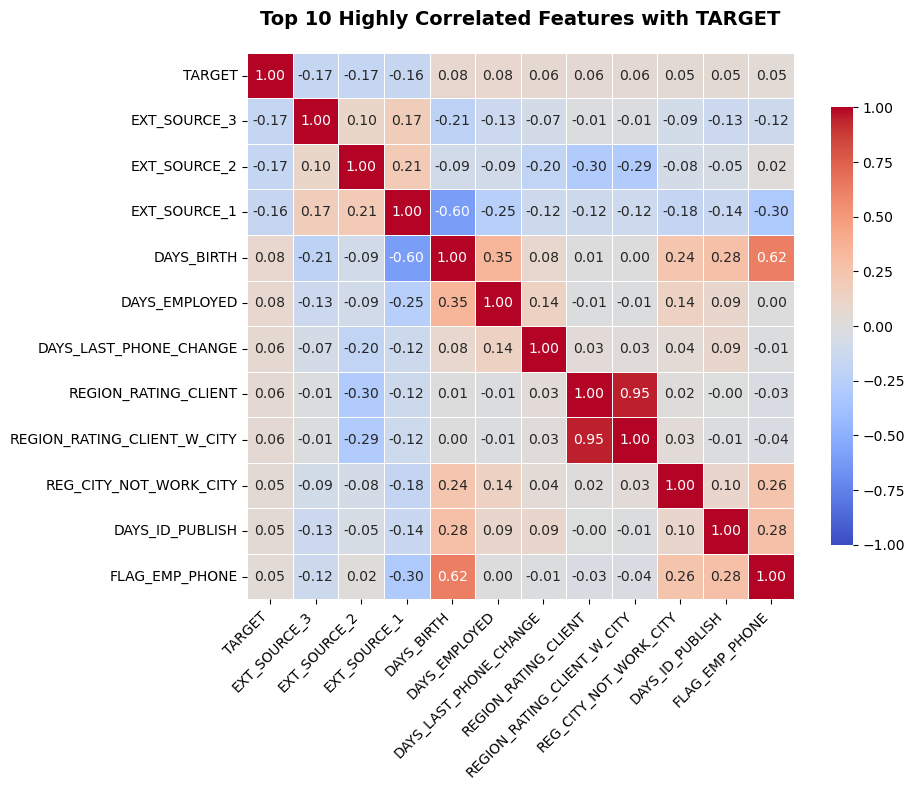

In [18]:

## Advanced Correlation Matrix with TARGET Variable with visulaization

numeric_cols = app_train.select_dtypes(include=[np.number])


top_corr_features = numeric_cols.corr()['TARGET'].abs().sort_values(ascending=False).head(12).index


top_corr_matrix = numeric_cols[top_corr_features].corr()


plt.figure(figsize=(10, 8))


sns.heatmap(top_corr_matrix, 
            annot=True, 
            fmt=".2f", 
            cmap="coolwarm", 
            vmin=-1, vmax=1, center=0, 
            square=True, 
            linewidths=0.5, 
            cbar_kws={"shrink": .8})

plt.title('Top 10 Highly Correlated Features with TARGET', fontsize=14, fontweight='bold', pad=20)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


## Insights 

• __Strongest Risk Predictors(EXT_SOURCE_1, 2, 3)__: These external bureau scores show the strongest negative correlation (-0.16 to -0.17) with the TARGET, meaning lower external credit scores drastically increase a customer's loan default risk.


• __Age vs Risk Factor (DAYS_BIRTH)__: There is a positive correlation (0.08) with the TARGET. Since age is recorded in negative days, this statistically indicates that younger applicants carry a higher probability of defaulting compared to older, more stable borrowers.

• __Geographical Risk Profile (REGION_RATING_CLIENT)__: The region rating variables hold a positive correlation (0.06) with the default target, revealing that applicants living in lower-rated regions or cities pose a slightly higher credit risk to the bank.

• __Severe Multicollinearity Alert__: The heatmap shows a near-perfect positive correlation (0.95) between REGION_RATING_CLIENT and REGION_RATING_CLIENT_W_CITY, meaning they provide redundant information and one should be dropped to avoid confusing the model.

• __Data Association Key__: A highly strong correlation (0.62) exists between FLAG_EMP_PHONE and DAYS_BIRTH, indicating that younger, actively employed applicants almost universally provide a verifiable workplace phone number during their application.

# 3. Feature Engineering and Data Aggregation 

In [19]:
# ------------------------------------------------------------------------------
# 3. MULTI-TABLE ADVANCED AGGREGATION (Merging All 7 Tables)
# ------------------------------------------------------------------------------

print("Running foolproof multi-table aggregation...")

# ---------------------------------------------------------
# 1. Bureau Balance -> Bureau
# ---------------------------------------------------------

# get only numeric column and drop other columns
burb_numeric = bureau_balance.select_dtypes(include=['number'])
burb_agg = burb_numeric.groupby('SK_ID_BUREAU').mean().reset_index()

# merge bureau data
bureau = bureau.merge(burb_agg, on='SK_ID_BUREAU', how='left')

# ---------------------------------------------------------
# 2. Safe Aggregation Function (for all tables)
# ---------------------------------------------------------
def get_safe_mean_df(df, prefix):
    """
    Kiski bhi dataframe se non-numeric data ko hamesha ke liye 
    saaf karke sirf numeric fields ka mean nikalne ka safe function
    """
    
    for col in df.columns:
        if col not in ['SK_ID_CURR', 'SK_ID_PREV', 'SK_ID_BUREAU']:
            df[col] = pd.to_numeric(df[col], errors='coerce')
            
    
    df_numeric = df.select_dtypes(include=['number'])
    
    
    if 'SK_ID_CURR' not in df_numeric.columns and 'SK_ID_CURR' in df.columns:
        df_numeric['SK_ID_CURR'] = df['SK_ID_CURR']
        
   
    agg_df = df_numeric.groupby('SK_ID_CURR').mean().reset_index()
    
    
    agg_df.columns = [prefix + col if col != 'SK_ID_CURR' else col for col in agg_df.columns]
    return agg_df

# ---------------------------------------------------------
# 3. Apply Safe Function on All Tables
# ---------------------------------------------------------
print("Aggregating individual tables safely...")
bureau_agg = get_safe_mean_df(bureau.drop(columns=['SK_ID_BUREAU'], errors='ignore'), 'BUR_')
prev_agg   = get_safe_mean_df(prev_app.drop(columns=['SK_ID_PREV'], errors='ignore'), 'PREV_')
pos_agg    = get_safe_mean_df(pos_cash.drop(columns=['SK_ID_PREV'], errors='ignore'), 'POS_')
cc_agg     = get_safe_mean_df(credit_card.drop(columns=['SK_ID_PREV'], errors='ignore'), 'CC_')
inst_agg   = get_safe_mean_df(installments.drop(columns=['SK_ID_PREV'], errors='ignore'), 'INST_')

# ---------------------------------------------------------------------
# 4. Master Merge (all date set merge into application_train data set)
# ---------------------------------------------------------------------
print("Merging all tables into Master Dataset...")
final_df = app_train.merge(bureau_agg, on='SK_ID_CURR', how='left') \
                     .merge(prev_agg, on='SK_ID_CURR', how='left') \
                     .merge(pos_agg, on='SK_ID_CURR', how='left') \
                     .merge(cc_agg, on='SK_ID_CURR', how='left') \
                     .merge(inst_agg, on='SK_ID_CURR', how='left')

print(f"Master Dataset Shape after fix: {final_df.shape}")



Running foolproof multi-table aggregation...
Aggregating individual tables safely...
Merging all tables into Master Dataset...
Master Dataset Shape after fix: (50000, 207)


In [20]:
final_df.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,CC_CNT_INSTALMENT_MATURE_CUM,CC_NAME_CONTRACT_STATUS,CC_SK_DPD,CC_SK_DPD_DEF,INST_NUM_INSTALMENT_VERSION,INST_NUM_INSTALMENT_NUMBER,INST_DAYS_INSTALMENT,INST_DAYS_ENTRY_PAYMENT,INST_AMT_INSTALMENT,INST_AMT_PAYMENT
0,384575,0,Cash loans,M,Y,N,2,207000.0,465457.5,52641.0,...,NaN,NaN,NaN,NaN,1.000000,6.103448,-1907.482759,-1915.448276,4168.131207,3016.967586
1,214010,0,Cash loans,F,Y,Y,0,247500.0,1281712.5,48946.5,...,1.857143,NaN,0.0,0.0,0.614286,10.557143,-877.900000,-887.342857,48174.739714,47918.993143
2,142232,0,Cash loans,F,Y,N,0,202500.0,495000.0,39109.5,...,NaN,NaN,NaN,NaN,1.000000,4.894737,-689.578947,-708.000000,12561.986842,11787.932368
3,389171,0,Cash loans,F,N,Y,0,247500.0,254700.0,24939.0,...,NaN,NaN,NaN,NaN,1.000000,6.923077,-1791.307692,-1761.692308,11225.831538,10361.146154
4,283617,0,Cash loans,M,N,Y,0,112500.0,308133.0,15862.5,...,0.000000,NaN,0.0,0.0,1.103448,5.689655,-1216.724138,-1229.965517,22811.576897,19119.950690


# 4. Data Preprocessing

### 4.1 Encoding 

In [21]:
## import LabelEncoder and Standard scaler 

from sklearn.preprocessing import LabelEncoder, StandardScaler

le = LabelEncoder()
for col in final_df.select_dtypes(include=['object']).columns:
    final_df[col] = le.fit_transform(final_df[col].astype(str))

## Feature Selection
X = final_df.drop(columns=['TARGET', 'SK_ID_CURR'])
y = final_df['TARGET']

### 4.2 Train_test Split (80% Train , 20% Test)

In [22]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [23]:
X_train.head()

,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,...,CC_CNT_INSTALMENT_MATURE_CUM,CC_NAME_CONTRACT_STATUS,CC_SK_DPD,CC_SK_DPD_DEF,INST_NUM_INSTALMENT_VERSION,INST_NUM_INSTALMENT_NUMBER,INST_DAYS_INSTALMENT,INST_DAYS_ENTRY_PAYMENT,INST_AMT_INSTALMENT,INST_AMT_PAYMENT
29721,1,0,0,0,0,99000.0,135000.0,6750.0,135000.0,6,...,NaN,NaN,NaN,NaN,1.0,4.4375,-1690.5,-1650.375,6611.295938,4945.215938
20450,0,1,1,1,0,270000.0,284400.0,17064.0,225000.0,6,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
30690,0,0,1,0,0,135000.0,625536.0,19768.5,540000.0,6,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7685,0,1,1,0,0,270000.0,1800000.0,49500.0,1800000.0,6,...,NaN,NaN,NaN,NaN,1.1,3.1000,-1691.2,-1695.200,78040.134000,78040.134000
46846,0,0,0,1,2,135000.0,1080000.0,40023.0,1080000.0,6,...,NaN,NaN,NaN,NaN,1.0,4.5000,-108.0,-122.375,5845.905000,5845.905000


In [24]:
y_test

46716    0
30062    0
38128    0
44152    0
3183     0
        ..
161      0
14089    0
34712    1
45515    0
28602    0
Name: TARGET, Length: 10000, dtype: int64

### 4.3 Missing Value Imputation(using Median)

In [25]:
# Imputation using Median
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy='median')
X_train_clean = imputer.fit_transform(X_train)
X_test_clean = imputer.transform(X_test)

In [26]:
X_train_clean

array([[ 1.00000000e+00,  0.00000000e+00,  0.00000000e+00, ...,
        -1.65037500e+03,  6.61129594e+03,  4.94521594e+03],
       [ 0.00000000e+00,  1.00000000e+00,  1.00000000e+00, ...,
        -8.05500000e+02,  1.25952718e+04,  1.22422209e+04],
       [ 0.00000000e+00,  0.00000000e+00,  1.00000000e+00, ...,
        -8.05500000e+02,  1.25952718e+04,  1.22422209e+04],
       ...,
       [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00, ...,
        -1.56492623e+03,  2.67952906e+03,  2.62420119e+03],
       [ 0.00000000e+00,  1.00000000e+00,  0.00000000e+00, ...,
        -8.05500000e+02,  1.25952718e+04,  1.22422209e+04],
       [ 0.00000000e+00,  1.00000000e+00,  0.00000000e+00, ...,
        -5.01581818e+02,  1.72361635e+04,  1.72361635e+04]],
      shape=(40000, 184))

In [27]:
X_test_clean

array([[ 1.00000000e+00,  0.00000000e+00,  0.00000000e+00, ...,
        -1.01500000e+02,  6.62916375e+03,  6.62916375e+03],
       [ 0.00000000e+00,  1.00000000e+00,  0.00000000e+00, ...,
        -1.09737500e+03,  5.51509237e+04,  5.57074059e+04],
       [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00, ...,
        -4.17068966e+02,  1.88030964e+04,  3.05503945e+04],
       ...,
       [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00, ...,
        -5.61029412e+02,  1.63328281e+04,  1.63328281e+04],
       [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00, ...,
        -2.00872973e+03,  1.52969327e+04,  1.46453546e+04],
       [ 0.00000000e+00,  1.00000000e+00,  1.00000000e+00, ...,
        -1.02800000e+03,  1.03685850e+04,  9.17760556e+03]],
      shape=(10000, 184))

### 4.4 Feature Scaling 

In [28]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_clean)
X_test_scaled = scaler.transform(X_test_clean)

In [29]:
X_train_scaled

array([[ 3.11877162, -0.71766061, -0.71610201, ..., -1.26114889,
        -0.53974193, -0.57936582],
       [-0.32063906,  1.3931059 ,  1.39644909, ...,  0.18969711,
        -0.2530931 , -0.26032102],
       [-0.32063906, -0.71766061,  1.39644909, ...,  0.18969711,
        -0.2530931 , -0.26032102],
       ...,
       [-0.32063906, -0.71766061, -0.71610201, ..., -1.11441357,
        -0.72808432, -0.68084686],
       [-0.32063906,  1.3931059 , -0.71610201, ...,  0.18969711,
        -0.2530931 , -0.26032102],
       [-0.32063906,  1.3931059 , -0.71610201, ...,  0.711595  ,
        -0.03078169, -0.04197234]], shape=(40000, 184))

In [30]:
X_test_scaled

array([[ 3.11877162, -0.71766061, -0.71610201, ...,  1.39862812,
        -0.53888601, -0.50573907],
       [-0.32063906,  1.3931059 , -0.71610201, ..., -0.31151985,
         1.78543912,  1.64009445],
       [-0.32063906, -0.71766061, -0.71610201, ...,  0.85672314,
         0.04427869,  0.54016186],
       ...,
       [-0.32063906, -0.71766061, -0.71610201, ...,  0.60950972,
        -0.07405393, -0.08146861],
       [-0.32063906, -0.71766061, -0.71610201, ..., -1.87652694,
        -0.12367615, -0.15524952],
       [-0.32063906,  1.3931059 ,  1.39644909, ..., -0.19238691,
        -0.3597575 , -0.3943143 ]], shape=(10000, 184))

# 5. Model Training & Evaluation

In [31]:
## Import Manchine learning Models
!pip install lightgbm

In [32]:
## import Required Model 

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier

## 5.1 Logistic Regression

In [33]:
print("\n--- Training Logistic Regression ---")
lr_model = LogisticRegression(max_iter=1000, class_weight='balanced')
lr_model.fit(X_train_scaled, y_train)



--- Training Logistic Regression ---


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [34]:
lr_preds = lr_model.predict_proba(X_test_scaled)[:, 1]
lr_class = lr_model.predict(X_test_scaled)

In [35]:
from sklearn.metrics import classification_report, roc_auc_score, accuracy_score, confusion_matrix

In [36]:

accuracy = accuracy_score(y_test, lr_class)
print(f"Accuracy Score: {accuracy:.4f}")


print("\n--- Classification Report ---")
print(classification_report(y_test, lr_class))

roc_auc = roc_auc_score(y_test, lr_preds)
print(f"ROC-AUC Score: {roc_auc:.4f}")

Accuracy Score: 0.6918

--- Classification Report ---
              precision    recall  f1-score   support

           0       0.96      0.69      0.81      9195
           1       0.16      0.68      0.26       805

    accuracy                           0.69     10000
   macro avg       0.56      0.69      0.53     10000
weighted avg       0.90      0.69      0.76     10000

ROC-AUC Score: 0.7563


## 5.2 Random Forest 

In [37]:
print("--- Training Random Forest ---")
rf_model = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, class_weight='balanced', n_jobs=-1)
rf_model.fit(X_train_clean, y_train)

--- Training Random Forest ---


,n_estimators,100
,criterion,'gini'
,max_depth,10
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [38]:
rf_preds = rf_model.predict_proba(X_test_clean)[:, 1]
rf_class = rf_model.predict(X_test_clean)

In [39]:
accuracy = accuracy_score(y_test, rf_class)
print(f"Accuracy Score: {accuracy:.4f}")

print("\n--- Classification Report ---")
print(classification_report(y_test, rf_class))

roc_auc = roc_auc_score(y_test, rf_preds)
print(f"ROC-AUC Score: {roc_auc:.4f}")

Accuracy Score: 0.8202

--- Classification Report ---
              precision    recall  f1-score   support

           0       0.94      0.86      0.90      9195
           1       0.20      0.41      0.27       805

    accuracy                           0.82     10000
   macro avg       0.57      0.63      0.58     10000
weighted avg       0.88      0.82      0.85     10000

ROC-AUC Score: 0.7264


## 5.3 LightGBM

In [40]:
print("--- Training LightGBM ---")
lgb_model = LGBMClassifier(n_estimators=500, learning_rate=0.05, class_weight='balanced', random_state=42, n_jobs=-1)
lgb_model.fit(X_train_clean, y_train)

--- Training LightGBM ---
[LightGBM] [Info] Number of positive: 3218, number of negative: 36782
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.068378 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 25127
[LightGBM] [Info] Number of data points in the train set: 40000, number of used features: 176
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000


,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.05
,n_estimators,500
,subsample_for_bin,200000
,objective,None
,class_weight,'balanced'
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,20


In [41]:
lgb_preds = lgb_model.predict_proba(X_test_clean)[:, 1]
lgb_class = lgb_model.predict(X_test_clean)

In [42]:
accuracy = accuracy_score(y_test, lgb_class)
print(f"Accuracy Score: {accuracy:.4f}")


print("\n--- Classification Report ---")
print(classification_report(y_test, lgb_class))

roc_auc = roc_auc_score(y_test, lgb_preds)
print(f"ROC-AUC Score: {roc_auc:.4f}")

Accuracy Score: 0.8343

--- Classification Report ---
              precision    recall  f1-score   support

           0       0.94      0.87      0.91      9195
           1       0.22      0.41      0.29       805

    accuracy                           0.83     10000
   macro avg       0.58      0.64      0.60     10000
weighted avg       0.89      0.83      0.86     10000

ROC-AUC Score: 0.7483


# Performance Comparison Metrics

In [43]:
# ==============================================================================
# PERFORMANCE COMPARISON METRICS
# ==============================================================================

print("\n=================== MODEL EVALUATION METRICS ===================")
print(f"Logistic Regression ROC-AUC: {roc_auc_score(y_test, lr_preds):.4f} | Accuracy: {accuracy_score(y_test, lr_class):.4f}")
print(f"Random Forest Classifier ROC-AUC: {roc_auc_score(y_test, rf_preds):.4f} | Accuracy: {accuracy_score(y_test, rf_class):.4f}")
print(f"LightGBM Classifier ROC-AUC: {roc_auc_score(y_test, lgb_preds):.4f} | Accuracy: {accuracy_score(y_test, lgb_class):.4f}")
print("================================================================")

# LightGBM Detail Classification Report 
print("\nLightGBM Detailed Classification Report:")
print(classification_report(y_test, lgb_class))


=================== MODEL EVALUATION METRICS ===================
Logistic Regression ROC-AUC: 0.7563 | Accuracy: 0.6918
Random Forest Classifier ROC-AUC: 0.7264 | Accuracy: 0.8202
LightGBM Classifier ROC-AUC: 0.7483 | Accuracy: 0.8343

LightGBM Detailed Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.87      0.91      9195
           1       0.22      0.41      0.29       805

    accuracy                           0.83     10000
   macro avg       0.58      0.64      0.60     10000
weighted avg       0.89      0.83      0.86     10000



In [44]:
# ==============================================================================
# MODEL COMPARISON REPORT 
# ==============================================================================
import pandas as pd


data = {
    'Model Name': ['Logistic Regression', 'Random Forest', 'LightGBM Classifier'],
    'ROC-AUC Score': ['0.7563', '0.7264', '0.7483'],
    'Test Accuracy': ['69.18%', '82.02%', '83.43%'],
    'Production Recommendation': [
        'Base Model (Good ROC-AUC, Low Accuracy)', 
        'Stable Model (High Accuracy, Low ROC-AUC)', 
        '⭐ Top Pick (Best Balance of Accuracy & ROC-AUC)'
    ]
}

df_report = pd.DataFrame(data)


print("=" * 40)
print("         MODEL COMPARISON REPORT         ")
print("=" * 40)

print(df_report.to_string(index=False))
print("=" * 80)
       

         MODEL COMPARISON REPORT         
         Model Name ROC-AUC Score Test Accuracy                       Production Recommendation
Logistic Regression        0.7563        69.18%         Base Model (Good ROC-AUC, Low Accuracy)
      Random Forest        0.7264        82.02%       Stable Model (High Accuracy, Low ROC-AUC)
LightGBM Classifier        0.7483        83.43% ⭐ Top Pick (Best Balance of Accuracy & ROC-AUC)
